In [ ]:
from pathlib import Path

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "requirements.txt").is_file() and (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("project_cos 폴더에서 노트북을 실행하세요.")
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
for name in ("figures", "tables", "runs"):
    (RESULTS_DIR / name).mkdir(parents=True, exist_ok=True)


In [2]:
import platform


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

zHD : 적색편이, m_b_corr : 겉보기등급

Text(0.5, 1.0, 'hubble_correlation')

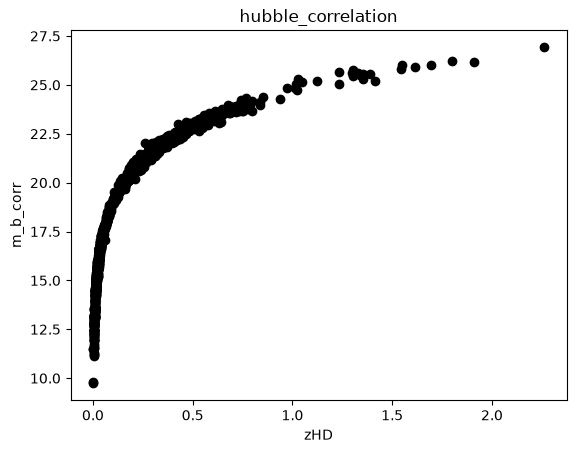

In [21]:
df = pd.read_csv(DATA_DIR / "Pantheon+SH0ES.dat", sep=r"\s+")

x = df["zHD"]
y = df["m_b_corr"]
plt.scatter(x,y, color = "black")
plt.xlabel("zHD")
plt.ylabel("m_b_corr")
plt.title("hubble_correlation")

In [27]:
filee = DATA_DIR / "Pantheon+SH0ES_STAT+SYS.cov"

with open(filee) as f:
    n = int(f.readline())

    C = np.loadtxt(f).reshape(n,n)

print(C.shape)

(1701, 1701)


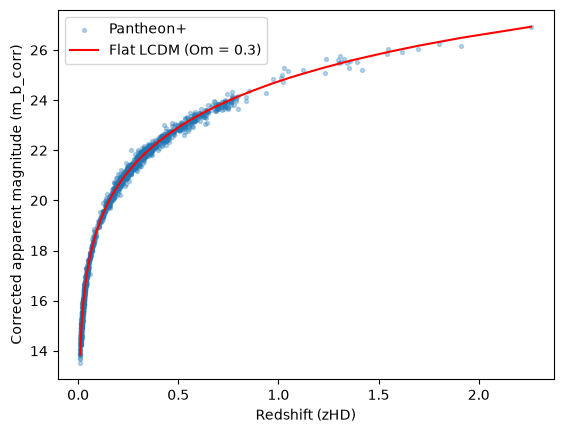

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# 그래프용 복사본을 만들어 원본 df의 행 순서를 보존
plot_df = df.loc[df["zHD"] > 0.01].sort_values("zHD")
z = plot_df["zHD"].to_numpy()
z_hel = plot_df["zHEL"].to_numpy()
m = plot_df["m_b_corr"].to_numpy()

omega_m = 0.3

def inverse_E(z):
    return 1 / np.sqrt(omega_m * (1 + z)**3 + 1 - omega_m)

distance = (1 + z_hel) * np.array([quad(inverse_E, 0, zi)[0] for zi in z])
shape = 5 * np.log10(distance)

offset = np.mean(m - shape)
m_model = shape + offset

plt.scatter(z, m, s=8, alpha=0.3, label="Pantheon+")
plt.plot(z, m_model, color="red", label="Flat LCDM (Om = 0.3)")
plt.xlabel("Redshift (zHD)")
plt.ylabel("Corrected apparent magnitude (m_b_corr)")

plt.legend()
plt.show()

In [31]:
import numpy as np

keep = df["zHD"].to_numpy() > 0.01
z = df["zHD"].to_numpy()[keep]
z_hel = df["zHEL"].to_numpy()[keep]
m = df["m_b_corr"].to_numpy()[keep]
cov = C[np.ix_(keep, keep)]

omega = np.linspace(0.01, 0.99, 981)
z_grid = np.linspace(0, z.max(), 5000)
dz = np.diff(z_grid)
shape = np.empty((len(z), len(omega)))

for j, om in enumerate(omega):
    inv_E = 1 / np.sqrt(om * (1 + z_grid)**3 + (1 - om))
    area = (inv_E[:-1] + inv_E[1:]) / 2 * dz
    integral = np.r_[0, np.cumsum(area)]
    distance = (1 + z_hel) * np.interp(z, z_grid, integral)
    shape[:, j] = 5 * np.log10(distance)

delta = m[:, None] - shape
ones = np.ones(len(z))
L = np.linalg.cholesky(cov)
weighted = np.linalg.solve(L, np.column_stack((ones, delta)))
u = weighted[:, 0]
d = weighted[:, 1:]

offset = (u @ d) / (u @ u)
chi2 = np.sum((d - u[:, None] * offset)**2, axis=0)

best = np.argmin(chi2)
print(f"최적 Ωm = {omega[best]:.3f}")
print(f"밝기 기준점 = {offset[best]:.3f}")
print(f"최소 χ² / 자유도 = {chi2[best]:.1f} / {len(z) - 2}")

최적 Ωm = 0.332
밝기 기준점 = 23.807
최소 χ² / 자유도 = 1402.9 / 1588


In [32]:
delta_chi2 = chi2 - chi2.min()
구간 = omega[delta_chi2 <= 1]
하한, 상한 = 구간.min(), 구간.max()

print(f"Ωm = {omega[best]:.3f} (+{상한 - omega[best]:.3f}, -{omega[best] - 하한:.3f})")
print(f"근사 68% 구간: {하한:.3f} ~ {상한:.3f}")

Ωm = 0.332 (+0.018, -0.018)
근사 68% 구간: 0.314 ~ 0.350


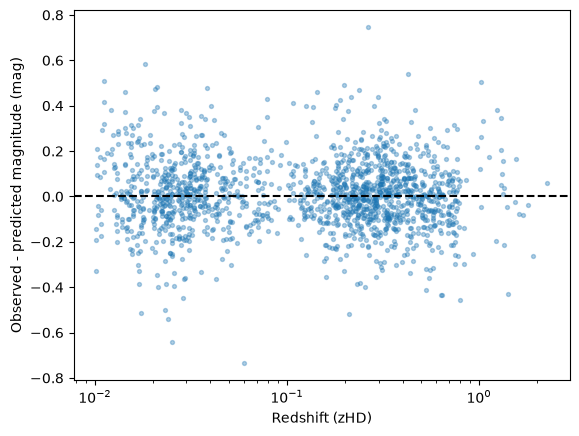

In [33]:
import matplotlib.pyplot as plt

예측등급 = shape[:, best] + offset[best]
잔차 = m - 예측등급

plt.scatter(z, 잔차, s=8, alpha=0.35)
plt.axhline(0, color="black", linestyle="--")
plt.xscale("log")
plt.xlabel("Redshift (zHD)")
plt.ylabel("Observed - predicted magnitude (mag)")
plt.show()

In [34]:
import subprocess
import sys

subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts/download_data.py")],
    check=True,
)
